In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility matching your EDA notebook (SEED = 42, IMG_SIZE = 224)
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
tf.keras.utils.set_random_seed(SEED)

# Muted low-glare academic palette for slide visuals
NAVY = "#1d4e89"
SAGE = "#52796f"

# Path to your EDA notebook's split folders (data/splits/train, val, test)
# If your notebook saved a manifest CSV instead, see the alternative loader note below
SPLIT_DIR = Path("dataset")

train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    crop_to_aspect_ratio=False,  # preserves full produce geometry
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "val",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    crop_to_aspect_ratio=False,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    crop_to_aspect_ratio=False,
    shuffle=False
)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

# Optimize input pipeline performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 402 files belonging to 8 classes.
Found 86 files belonging to 8 classes.
Found 87 files belonging to 8 classes.
Classes: ['apple', 'banana', 'carrot', 'cucumber', 'lemon', 'orange', 'potato', 'tomato']


W0000 00:00:1795631701.725589 3216542 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


FileNotFoundError: [Errno 2] No such file or directory: 'reports/augmentation_examples.png'

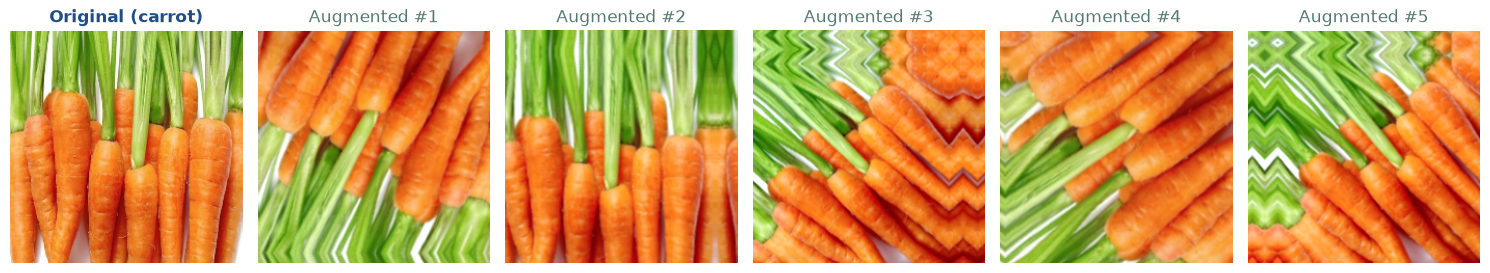

In [2]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.15, seed=SEED),
    layers.RandomZoom(0.15, seed=SEED),
    layers.RandomTranslation(0.1, 0.1, seed=SEED),
    layers.RandomContrast(0.2, seed=SEED),
], name="data_augmentation")

# Plot 1 original image + 5 augmented variations for your slide deck
for images, labels in train_ds.take(1):
    sample_img = images[0]
    sample_label = CLASS_NAMES[labels[0]]
    
    fig, axes = plt.subplots(1, 6, figsize=(15, 3))
    axes[0].imshow(sample_img.numpy().astype("uint8"))
    axes[0].set_title(f"Original ({sample_label})", fontweight="bold", color=NAVY)
    axes[0].axis("off")
    
    for i in range(1, 6):
        aug_img = data_augmentation(tf.expand_dims(sample_img, 0), training=True)[0]
        axes[i].imshow(np.clip(aug_img.numpy(), 0, 255).astype("uint8"))
        axes[i].set_title(f"Augmented #{i}", color=SAGE)
        axes[i].axis("off")
        
    plt.tight_layout()
    plt.savefig("reports/augmentation_examples.png", dpi=200, bbox_inches="tight")
    plt.show()

In [3]:
baseline_cnn = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Rescaling(1./255),

    # Conv Block 1: 16 filters, 3x3 kernel, zero-padding border ('same')
    layers.Conv2D(16, (3, 3), padding="same", activation="relu", name="conv1"),
    layers.MaxPooling2D((2, 2), name="pool1"),

    # Conv Block 2: 32 filters
    layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv2"),
    layers.MaxPooling2D((2, 2), name="pool2"),

    layers.GlobalAveragePooling2D(name="global_avg_pool"),
    layers.Dense(NUM_CLASSES, activation="softmax", name="output")
], name="Baseline_2Layer_CNN")

baseline_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_cnn.summary()

early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True
)

history_baseline = baseline_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop],
    verbose=1
)

Model: "Baseline_2Layer_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,352 (20.91 KB)

 Trainable params: 5,352 (20.91 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


/Users/dan/miniforge3/envs/ds_master/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - accuracy: 0.1343 - loss: 2.0854 - val_accuracy: 0.2093 - val_loss: 2.0622
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.1841 - loss: 2.0563 - val_accuracy: 0.1860 - val_loss: 2.0429
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.1915 - loss: 2.0353 - val_accuracy: 0.1860 - val_loss: 2.0188
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.1915 - loss: 2.0084 - val_accuracy: 0.2093 - val_loss: 1.9867
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.2114 - loss: 1.9728 - val_accuracy: 0.2093 - val_loss: 1.9450
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.2239 - loss: 1.9286 - val_accuracy: 0.2791 - val_loss: 1.8938
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.2910 - loss: 1.8760 - val_accuracy: 0.3256 - val_loss: 1.8404
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.3408 - loss: 1.8242 - val_accuracy: 0.3488 - val_loss: 1

In [4]:
advanced_cnn = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    # Conv Block 1
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 2
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Conv Block 3
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="Advanced_Custom_CNN")

advanced_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
)
early_stop_adv = callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

history_advanced = advanced_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[reduce_lr, early_stop_adv],
    verbose=1
)

Epoch 1/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 510ms/step - accuracy: 0.2363 - loss: 2.1362 - val_accuracy: 0.1395 - val_loss: 2.0593 - learning_rate: 0.0010
Epoch 2/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 496ms/step - accuracy: 0.3806 - loss: 1.6919 - val_accuracy: 0.2209 - val_loss: 2.0350 - learning_rate: 0.0010
Epoch 3/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 488ms/step - accuracy: 0.4154 - loss: 1.5309 - val_accuracy: 0.3140 - val_loss: 2.0066 - learning_rate: 0.0010
Epoch 4/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 491ms/step - accuracy: 0.5000 - loss: 1.3840 - val_accuracy: 0.1977 - val_loss: 1.9793 - learning_rate: 0.0010
Epoch 5/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 495ms/step - accuracy: 0.5299 - loss: 1.2979 - val_accuracy: 0.1860 - val_loss: 2.0067 - learning_rate: 0.0010
Epoch 6/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 495ms/step - accuracy: 0.5199 - loss: 1.2414 - val_accuracy: 0.1744 - val_loss: 2.0865 - learning_rate: 0.0010
Epoch 7/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 497ms/step - accuracy: 0.5821 - loss: 1.1132 - 

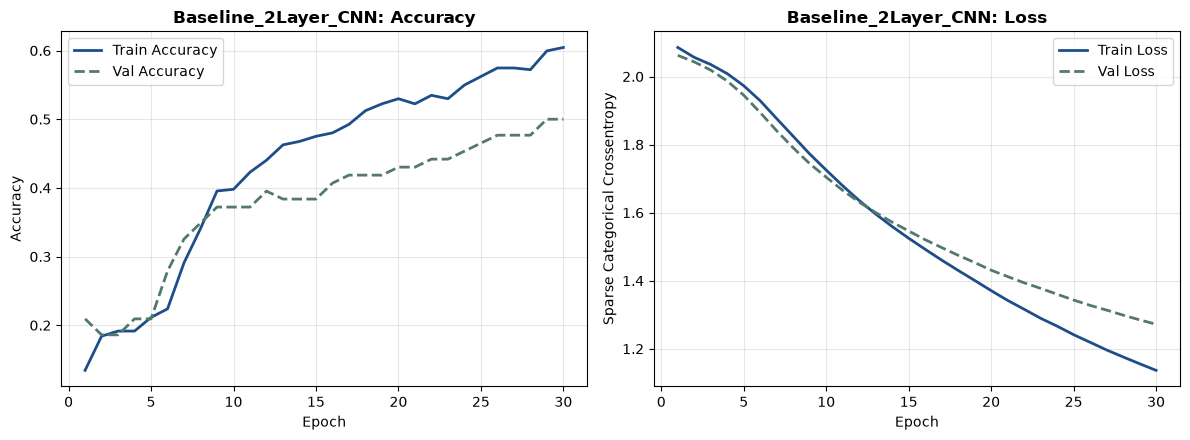


=== Baseline_2Layer_CNN Test Results ===
Test Loss: 1.1974 | Test Accuracy: 59.7701%

Classification Report:
              precision    recall  f1-score   support

       apple      0.579     0.688     0.629        16
      banana      0.429     0.300     0.353        10
      carrot      0.857     0.545     0.667        11
    cucumber      0.571     0.444     0.500         9
       lemon      0.409     0.900     0.562        10
      orange      0.800     0.444     0.571         9
      potato      0.818     0.750     0.783        12
      tomato      0.667     0.600     0.632        10

    accuracy                          0.598        87
   macro avg      0.641     0.584     0.587        87
weighted avg      0.642     0.598     0.596        87



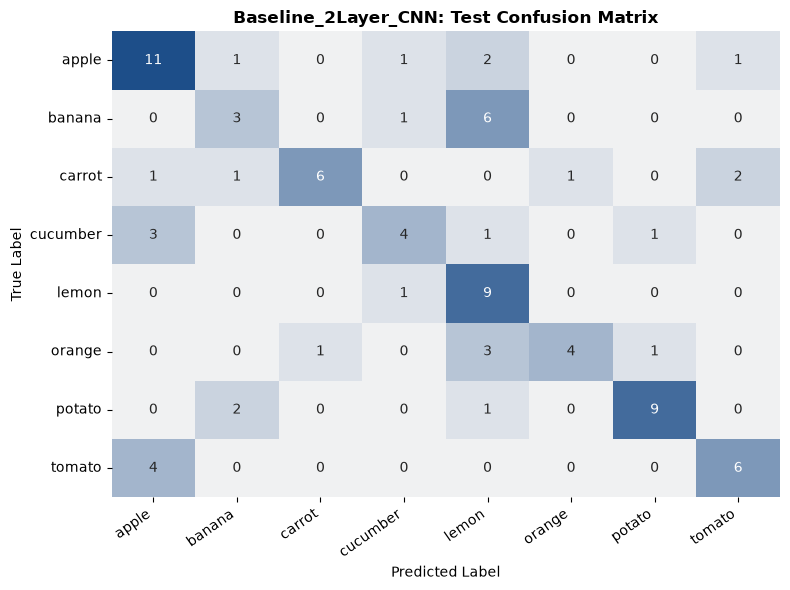

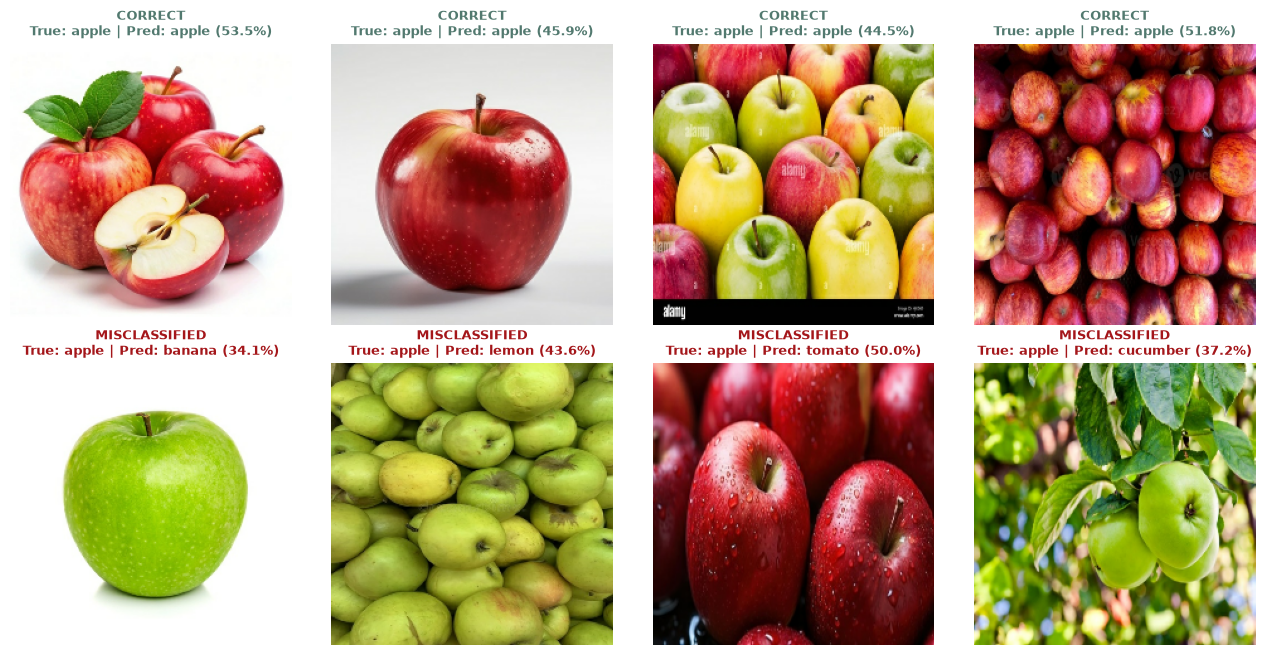

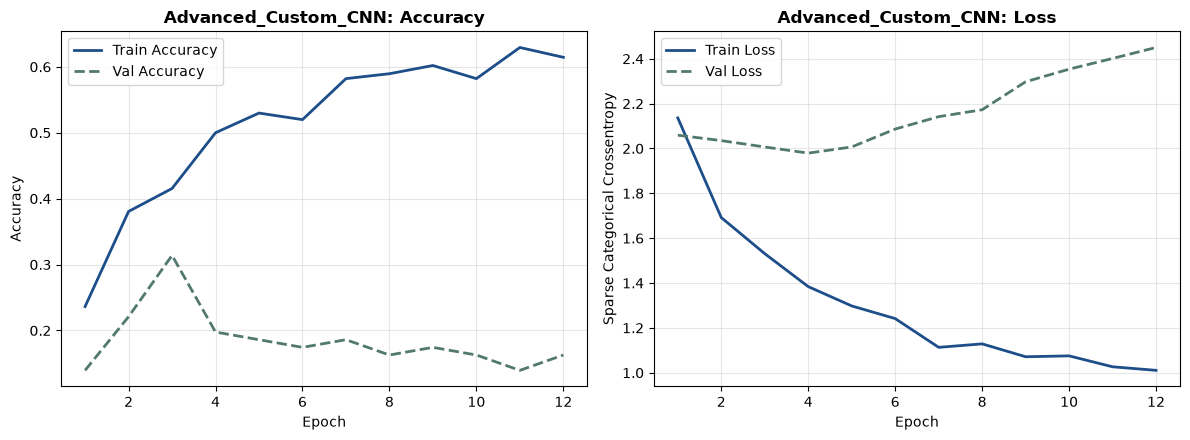


=== Advanced_Custom_CNN Test Results ===
Test Loss: 1.9849 | Test Accuracy: 22.9885%

Classification Report:
              precision    recall  f1-score   support

       apple      0.167     0.062     0.091        16
      banana      0.205     0.800     0.327        10
      carrot      0.000     0.000     0.000        11
    cucumber      0.000     0.000     0.000         9
       lemon      0.778     0.700     0.737        10
      orange      0.000     0.000     0.000         9
      potato      0.121     0.333     0.178        12
      tomato      0.000     0.000     0.000        10

    accuracy                          0.230        87
   macro avg      0.159     0.237     0.167        87
weighted avg      0.160     0.230     0.163        87



/Users/dan/miniforge3/envs/ds_master/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/dan/miniforge3/envs/ds_master/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/dan/miniforge3/envs/ds_master/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

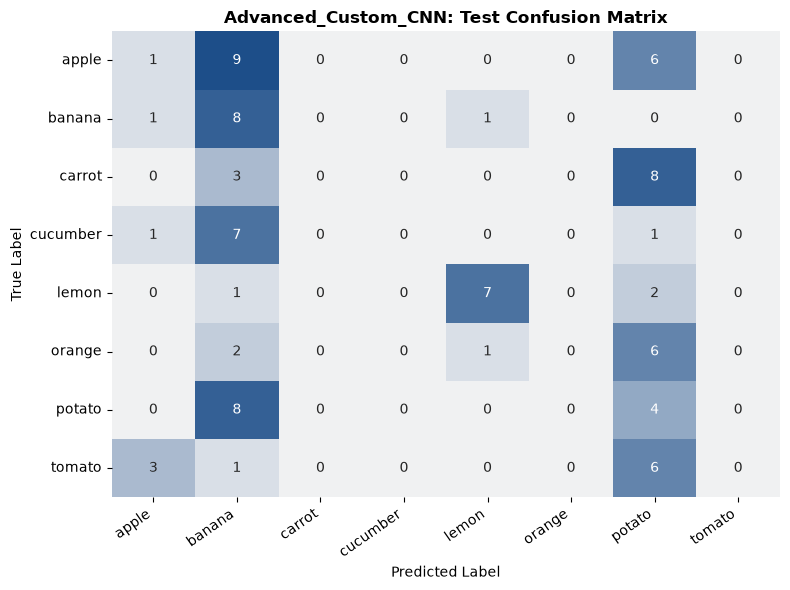

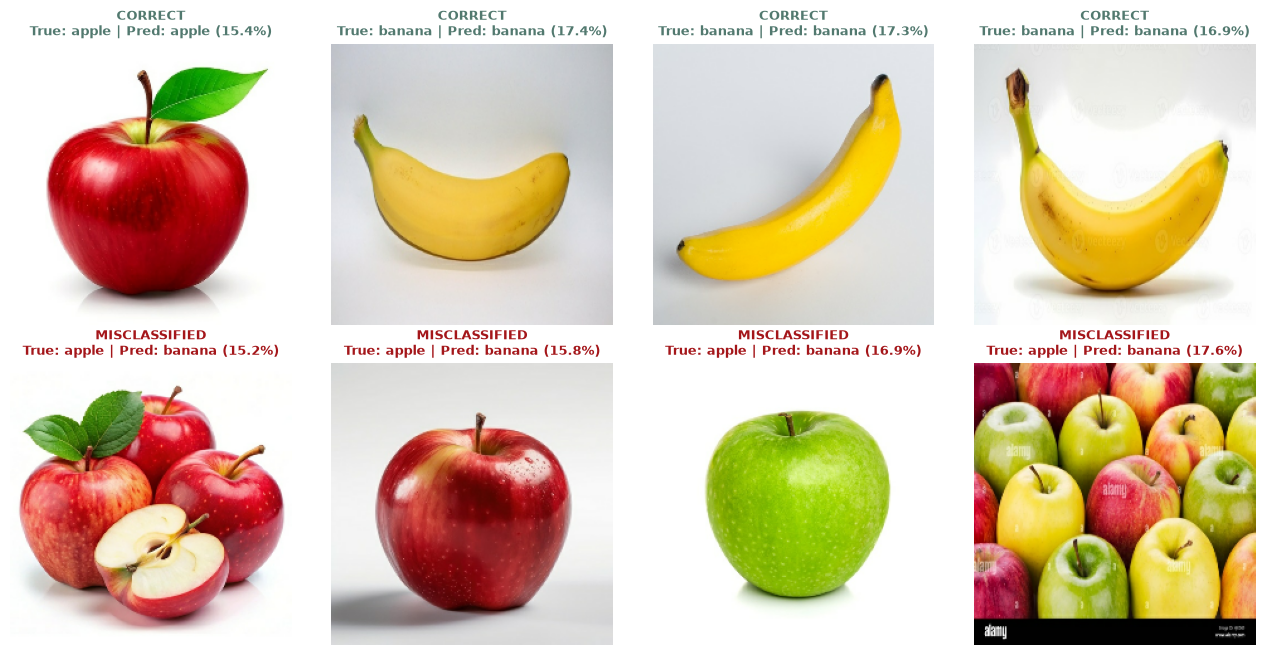

,Model,Test Loss,Test Accuracy
0,Baseline_2Layer_CNN,1.1974,0.5977
1,Advanced_Custom_CNN,1.9849,0.2299


In [5]:
def evaluate_and_diagnose(model, history, test_dataset, class_names, save_prefix):
    os.makedirs("reports", exist_ok=True)
    
    # 1. Training & Validation Accuracy / Loss Plots
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(epochs_range, hist["accuracy"], label="Train Accuracy", color=NAVY, linewidth=2)
    ax1.plot(epochs_range, hist["val_accuracy"], label="Val Accuracy", color=SAGE, linewidth=2, linestyle="--")
    ax1.set_title(f"{model.name}: Accuracy", fontweight="bold")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Accuracy")
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(epochs_range, hist["loss"], label="Train Loss", color=NAVY, linewidth=2)
    ax2.plot(epochs_range, hist["val_loss"], label="Val Loss", color=SAGE, linewidth=2, linestyle="--")
    ax2.set_title(f"{model.name}: Loss", fontweight="bold")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Sparse Categorical Crossentropy")
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"reports/{save_prefix}_curves.png", dpi=200, bbox_inches="tight")
    plt.show()

    # 2. Test Set Evaluation & Predictions
    test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
    print(f"\n=== {model.name} Test Results ===")
    print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4%}\n")

    y_true, y_probs, sample_imgs = [], [], []
    for imgs, lbls in test_dataset:
        preds = model.predict(imgs, verbose=0)
        y_true.extend(lbls.numpy())
        y_probs.extend(preds)
        sample_imgs.extend(imgs.numpy())

    y_true = np.array(y_true)
    y_probs = np.array(y_probs)
    y_pred = np.argmax(y_probs, axis=1)
    sample_imgs = np.array(sample_imgs)

    # 3. Classification Report (Precision, Recall, F1)
    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

    # 4. Confusion Matrix Heatmap
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=sns.light_palette(NAVY, as_cmap=True),
        xticklabels=class_names, yticklabels=class_names, cbar=False
    )
    plt.title(f"{model.name}: Test Confusion Matrix", fontweight="bold")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(f"reports/{save_prefix}_cm.png", dpi=200, bbox_inches="tight")
    plt.show()

    # 5. Sample Predictions Grid (4 Correct + 4 Misclassified)
    correct_idx = np.where(y_pred == y_true)[0]
    wrong_idx = np.where(y_pred != y_true)[0]
    chosen = list(correct_idx[:4]) + list(wrong_idx[:4])

    if chosen:
        cols = 4
        rows = int(np.ceil(len(chosen) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(13, 3.3 * rows))
        axes = np.atleast_1d(axes).flatten()
        
        for ax, idx in zip(axes, chosen):
            ax.imshow(sample_imgs[idx].astype("uint8"))
            is_ok = (y_pred[idx] == y_true[idx])
            conf = y_probs[idx][y_pred[idx]] * 100
            title_color = SAGE if is_ok else "#a4161a"
            status = "CORRECT" if is_ok else "MISCLASSIFIED"
            ax.set_title(
                f"{status}\nTrue: {class_names[y_true[idx]]} | Pred: {class_names[y_pred[idx]]} ({conf:.1f}%)",
                fontsize=9, fontweight="bold", color=title_color
            )
            ax.axis("off")
            
        for ax in axes[len(chosen):]:
            ax.axis("off")
            
        plt.tight_layout()
        plt.savefig(f"reports/{save_prefix}_predictions.png", dpi=200, bbox_inches="tight")
        plt.show()

    return {"Model": model.name, "Test Loss": round(test_loss, 4), "Test Accuracy": round(test_acc, 4)}

# Run diagnostics for both models and print side-by-side summary table
res_base = evaluate_and_diagnose(baseline_cnn, history_baseline, test_ds, CLASS_NAMES, "baseline_cnn")
res_adv = evaluate_and_diagnose(advanced_cnn, history_advanced, test_ds, CLASS_NAMES, "advanced_cnn")

summary_df = pd.DataFrame([res_base, res_adv])
display(summary_df)

In [6]:
from tensorflow.keras import layers, models, callbacks, regularizers

# Gentler augmentation without BatchNorm or mirrored border artifacts
data_augmentation_v2 = models.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.08, fill_mode="nearest", seed=SEED),
    layers.RandomZoom(0.10, fill_mode="nearest", seed=SEED),
], name="data_augmentation_v2")

advanced_cnn_v2 = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation_v2,
    layers.Rescaling(1./255),

    # Conv Block 1
    layers.Conv2D(24, (3, 3), padding="same", activation="relu",
                  kernel_regularizer=regularizers.l2(1e-4), name="conv1"),
    layers.MaxPooling2D((2, 2), name="pool1"),

    # Conv Block 2
    layers.Conv2D(48, (3, 3), padding="same", activation="relu",
                  kernel_regularizer=regularizers.l2(1e-4), name="conv2"),
    layers.MaxPooling2D((2, 2), name="pool2"),

    # Conv Block 3
    layers.Conv2D(64, (3, 3), padding="same", activation="relu",
                  kernel_regularizer=regularizers.l2(1e-4), name="conv3"),
    layers.MaxPooling2D((2, 2), name="pool3"),

    layers.GlobalAveragePooling2D(name="global_avg_pool"),
    layers.Dropout(0.3, name="dropout_head"),
    layers.Dense(64, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4), name="dense1"),
    layers.Dense(NUM_CLASSES, activation="softmax", name="output")
], name="Advanced_Custom_CNN_v2")

advanced_cnn_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

advanced_cnn_v2.summary()

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=1
)
early_stop_adv = callbacks.EarlyStopping(
    monitor="val_loss", patience=12, restore_best_weights=True, verbose=1
)

history_advanced_v2 = advanced_cnn_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[reduce_lr, early_stop_adv],
    verbose=1
)

Model: "Advanced_Custom_CNN_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_v2            │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 24)   │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 24)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 48)   │        10,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 64)     │        27,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,480 (169.84 KB)

 Trainable params: 43,480 (169.84 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


/Users/dan/miniforge3/envs/ds_master/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 207ms/step - accuracy: 0.1244 - loss: 2.0925 - val_accuracy: 0.1860 - val_loss: 2.0824 - learning_rate: 5.0000e-04
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 211ms/step - accuracy: 0.1965 - loss: 2.0744 - val_accuracy: 0.1860 - val_loss: 2.0676 - learning_rate: 5.0000e-04
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 209ms/step - accuracy: 0.1766 - loss: 2.0640 - val_accuracy: 0.1860 - val_loss: 2.0418 - learning_rate: 5.0000e-04
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step - accuracy: 0.1915 - loss: 2.0381 - val_accuracy: 0.1860 - val_loss: 2.0060 - learning_rate: 5.0000e-04
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 199ms/step - accuracy: 0.1791 - loss: 1.9894 - val_accuracy: 0.1860 - val_loss: 1.9487 - learning_rate: 5.0000e-04
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - accuracy: 0.2264 - loss: 1.9306 - val_accuracy: 0.2907 - val_loss: 1.8769 - learning_rate: 5.0000e-04
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - accuracy: 0.2836 - lo

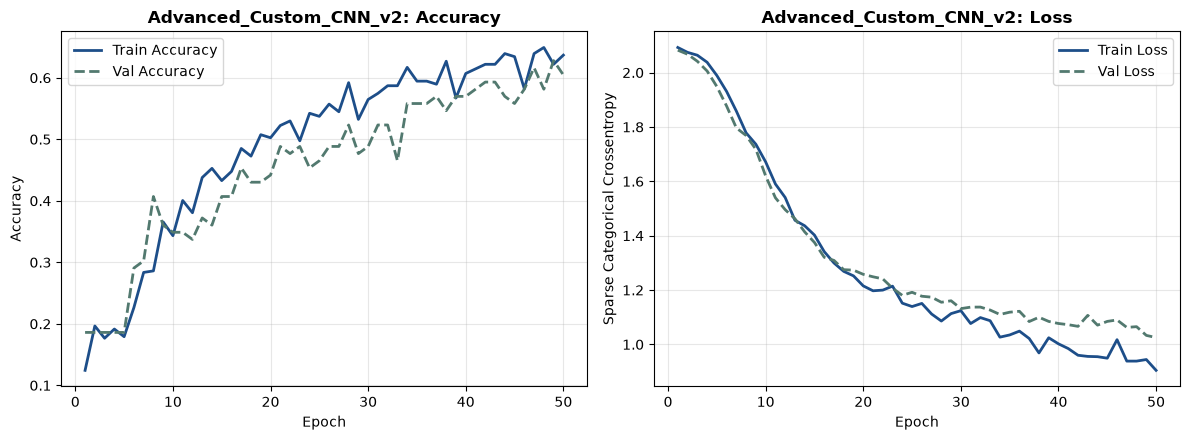


=== Advanced_Custom_CNN_v2 Test Results ===
Test Loss: 0.8234 | Test Accuracy: 65.5172%

Classification Report:
              precision    recall  f1-score   support

       apple      0.647     0.688     0.667        16
      banana      0.500     0.300     0.375        10
      carrot      0.733     1.000     0.846        11
    cucumber      0.556     0.556     0.556         9
       lemon      0.600     0.900     0.720        10
      orange      1.000     0.222     0.364         9
      potato      0.769     0.833     0.800        12
      tomato      0.600     0.600     0.600        10

    accuracy                          0.655        87
   macro avg      0.676     0.637     0.616        87
weighted avg      0.674     0.655     0.630        87



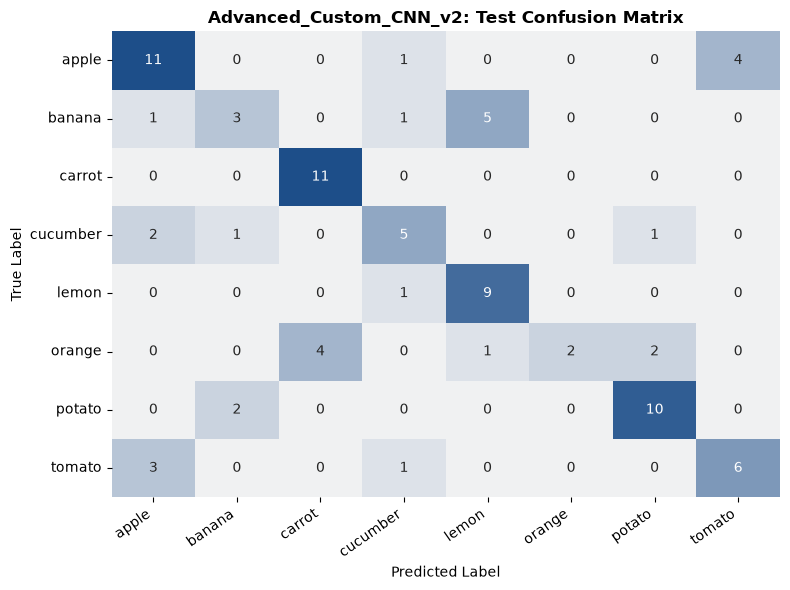

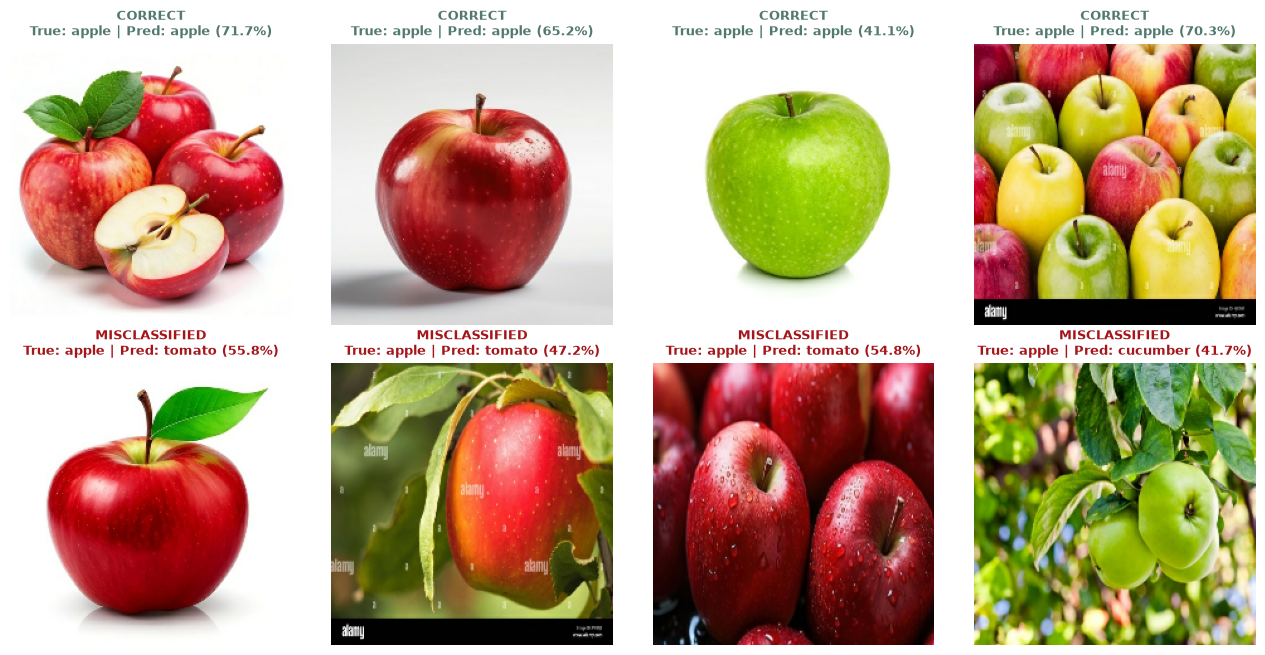

,Model,Test Loss,Test Accuracy
0,Baseline_2Layer_CNN,1.1974,0.5977
1,Advanced_Custom_CNN_v2,0.8234,0.6552


In [7]:
res_adv_v2 = evaluate_and_diagnose(
    advanced_cnn_v2,
    history_advanced_v2,
    test_ds,
    CLASS_NAMES,
    "advanced_cnn_v2"
)

# Side-by-side comparison table (rebuilds res_base from baseline_cnn if in memory)
if "res_base" in globals():
    comparison_df = pd.DataFrame([res_base, res_adv_v2])
    display(comparison_df)
else:
    display(pd.DataFrame([res_adv_v2]))